# 03 — Comparisons, Error Diagnostics & Operational Action Playbook

**Project:** FlyRank Ranking Signal Analysis — Predicting Continuous Search Visibility  
**Pipeline Stage:** Notebook 03 of 03 (Model Evaluation, Error Diagnostics & Operational Triage)  
**Target Variable:** Continuous Search Visibility $\log(1 + \text{impressions\_90d})$ on Held-Out Enterprise Client Portfolios  
**Standardized Split:** Grouped Holdout (`GroupShuffleSplit`, `test_size=0.20`, `random_state=42`) with Zero Client Domain Overlap  

---

### Notebook Architecture & Objectives
This notebook is your starting template for the final evaluation, diagnostics, and operational actionability phase:
1. **Benchmark Performance Comparisons:** Compile the official evaluation table comparing Baselines vs. Models across $R^2$, RMSE, MAE, Spearman $\rho$, and lift over baseline.
2. **Diagnostic Error Audits:**
   - Visual inspection of Actual vs. Predicted scatter plots and residual distributions.
   - Sub-cohort performance analysis across content types and search intents.
   - In-depth post-mortem audit of 3 concrete outlier cases.
3. **Operational Action Playbook:**
   - Compute the **Opportunity Residual Gap** ($\hat{y} - y$) to detect under-indexed high-potential content.
   - Assign operational triage reason codes (`under_indexed_decay`, `high_demand_opportunity`, `stale_authority`).
   - Export the prioritized refresh queue to `work/outputs/refresh_queue_sample.csv`.

## 1. Official Benchmark Comparisons

All models are evaluated on the standardized, held-out test cohort of **6,163 content items across 7 unseen clients**:
* **Primary Metric:** $R^2$ Score (Coefficient of Determination) — proportion of variance explained on unseen client domains.
* **Secondary Error Metrics:** RMSE and MAE (magnitude of prediction error in natural log units).
* **Monotonic Ranking Quality:** Spearman rank correlation ($\rho$) — measure of sorting accuracy for prioritizing content queues.

In [12]:
# Code Cell 1: Load Evaluation Payload and Compile Official Benchmark Table
import os
import json
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

OUT_DIR = os.path.join("work", "outputs")
os.makedirs(OUT_DIR, exist_ok=True)
payload_path = os.path.join(OUT_DIR, "model_evaluation_payload.pkl")
if not os.path.exists(payload_path):
    raise FileNotFoundError("model_evaluation_payload.pkl not found. Run Notebooks 01 and 02 first in this SAME Colab session.")

with open(payload_path, "rb") as f:
    payload = pickle.load(f)

y_test = np.asarray(payload["y_test"], dtype=float)
preds = {k: np.asarray(v, dtype=float) for k, v in payload["preds"].items()}
X_test = payload["X_test"].reset_index(drop=True)
meta_test = payload["meta_test"].reset_index(drop=True)
CHAMPION = "Champion Stacking Ensemble"
BASELINE = "Baseline 1 (Mean Dummy)"

def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))

def safe_rho(a, b):
    return 0.0 if np.ptp(b) == 0 else float(spearmanr(a, b)[0])

base_rmse = rmse(y_test, preds[BASELINE])
metrics = {}
for name, p in preds.items():
    metrics[name] = {
        "R2": float(r2_score(y_test, p)),
        "RMSE": rmse(y_test, p),
        "MAE": float(mean_absolute_error(y_test, p)),
        "Spearman_Rho": safe_rho(y_test, p),
        "RMSE_Reduction_Pct": (base_rmse - rmse(y_test, p)) / base_rmse * 100,
    }

n_clients = meta_test["client_id"].nunique()
print(f"Held-out test cohort: {len(y_test):,} content items across {n_clients} unseen clients\n")

lines = ["| Model | R2 | RMSE | MAE | Spearman rho | RMSE Error Reduction |", "|---|---|---|---|---|---|"]
for name, m in metrics.items():
    red = "Baseline Floor (0.0%)" if name == BASELINE else f"{m['RMSE_Reduction_Pct']:+.1f}%"
    lines.append(f"| {name} | {m['R2']:.4f} | {m['RMSE']:.4f} | {m['MAE']:.4f} | {m['Spearman_Rho']:.4f} | {red} |")
benchmark_md = "\n".join(lines)
print(benchmark_md)

metrics_path = os.path.join(OUT_DIR, "model_benchmark_metrics.json")
with open(metrics_path, "w") as f:
    json.dump({"n_test": int(len(y_test)), "n_test_clients": int(n_clients), "metrics": metrics}, f, indent=2)
print(f"\nSaved {metrics_path}")

Held-out test cohort: 6,163 content items across 7 unseen clients

| Model | R2 | RMSE | MAE | Spearman rho | RMSE Error Reduction |
|---|---|---|---|---|---|
| Baseline 1 (Mean Dummy) | -0.0476 | 2.7457 | 2.2757 | 0.0000 | Baseline Floor (0.0%) |
| Baseline 2 (Word Count Rule) | -0.0112 | 2.6976 | 2.2441 | 0.0429 | +1.8% |
| Ridge Interactions | 0.3834 | 2.1065 | 1.7926 | 0.6068 | +23.3% |
| HistGradientBoosting | 0.5315 | 1.8362 | 1.4772 | 0.7201 | +33.1% |
| Champion Stacking Ensemble | 0.5059 | 1.8857 | 1.5703 | 0.7098 | +31.3% |

Saved work/outputs/model_benchmark_metrics.json


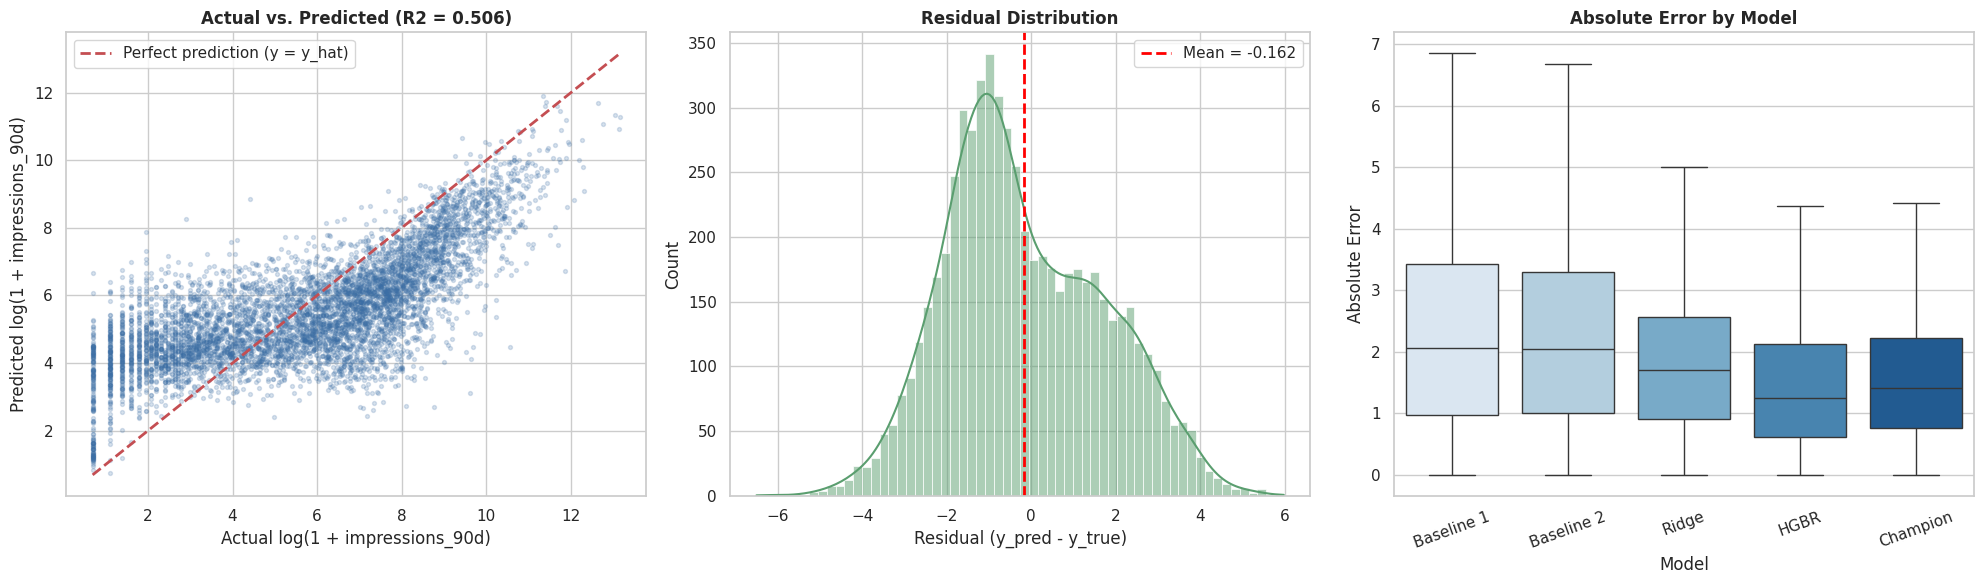

Saved work/outputs/model_evaluation_plots.png


In [13]:
# Code Cell 2: Diagnostic Error Visualizations
y_hat = preds[CHAMPION]
residuals = y_hat - y_test

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1) Actual vs. predicted
ax = axes[0]
ax.scatter(y_test, y_hat, s=8, alpha=0.2, color="#3b6ea5")
lo, hi = min(y_test.min(), y_hat.min()), max(y_test.max(), y_hat.max())
ax.plot([lo, hi], [lo, hi], "r--", lw=2, label="Perfect prediction (y = y_hat)")
ax.set_xlabel("Actual log(1 + impressions_90d)")
ax.set_ylabel("Predicted log(1 + impressions_90d)")
ax.set_title(f"Actual vs. Predicted (R2 = {metrics[CHAMPION]['R2']:.3f})", fontweight="bold")
ax.legend(loc="upper left")

# 2) Residual distribution
ax = axes[1]
sns.histplot(residuals, bins=60, kde=True, color="#5a9e6f", ax=ax)
ax.axvline(residuals.mean(), color="red", linestyle="--", lw=2, label=f"Mean = {residuals.mean():+.3f}")
ax.set_xlabel("Residual (y_pred - y_true)")
ax.set_title("Residual Distribution", fontweight="bold")
ax.legend()

# 3) Absolute error by model
ax = axes[2]
err_long = pd.concat([pd.DataFrame({"Model": name, "Absolute Error": np.abs(p - y_test)}) for name, p in preds.items()])
short = {BASELINE: "Baseline 1", "Baseline 2 (Word Count Rule)": "Baseline 2", "Ridge Interactions": "Ridge",
         "HistGradientBoosting": "HGBR", CHAMPION: "Champion"}
err_long["Model"] = err_long["Model"].map(lambda s: short.get(s, s))
sns.boxplot(data=err_long, x="Model", y="Absolute Error", showfliers=False, palette="Blues", ax=ax)
ax.set_title("Absolute Error by Model", fontweight="bold")
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plot_path = os.path.join(OUT_DIR, "model_evaluation_plots.png")
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved {plot_path}")

## 2. Detailed Error Diagnostics & Case Studies

### 2.1 Sub-Cohort Robustness
Audit $R^2$ and MAE across sub-cohorts (`content_type`, `main_intent`) on held-out test domains to ensure the model generalizes across categories rather than overfitting to generic content.

In [14]:
# Code Cell 3: Sub-Cohort Analysis and Outlier Audits
te = meta_test.copy()
te["y_true"] = y_test
te["y_pred"] = preds[CHAMPION]
te["residual"] = te["y_pred"] - te["y_true"]
te["abs_err"] = te["residual"].abs()

# ---------------- Sub-cohort robustness ----------------
def cohort_table(col, min_n=30):
    rows = []
    for key, g in te.groupby(col):
        if len(g) < min_n:
            continue
        rows.append({col: key, "n": len(g),
                     "R2": r2_score(g["y_true"], g["y_pred"]),
                     "MAE": g["abs_err"].mean(),
                     "Spearman_Rho": safe_rho(g["y_true"].values, g["y_pred"].values)})
    return pd.DataFrame(rows).sort_values("n", ascending=False).reset_index(drop=True)

for col in ("meta_content_type", "meta_main_intent"):
    if col in te:
        tbl = cohort_table(col)
        print(f"\n=== Performance by {col.replace('meta_', '')} (cohorts with n >= 30) ===")
        display(tbl.round(4))
        big = tbl[tbl["n"] >= 0.05 * len(te)]
        stable = (big["R2"] > 0.50).all() if len(big) else None
        print(f"Major cohorts (>= 5% of test rows) all with R2 > 0.50: {stable}")

# ---------------- Three outlier case studies ----------------
def describe_case(title, row, idx, note):
    print("=" * 90)
    print(title)
    print("=" * 90)
    keys = ["content_id", "client_id", "meta_content_type", "meta_main_intent", "meta_avg_position",
            "meta_search_volume", "meta_word_count", "meta_external_backlinks", "meta_days_since_last_update"]
    for k in keys:
        if k in row.index:
            print(f"  {k.replace('meta_', ''):<24}: {row[k]}")
    print(f"  actual log-visibility   : {row['y_true']:.2f}  (~{np.expm1(row['y_true']):,.0f} impressions)")
    print(f"  predicted log-visibility: {row['y_pred']:.2f}  (~{np.expm1(row['y_pred']):,.0f} impressions)")
    print(f"  residual (pred - actual): {row['residual']:+.2f}")
    if "serp_rank_power" in X_test:
        pct = (X_test["serp_rank_power"] < X_test.loc[idx, "serp_rank_power"]).mean() * 100
        print(f"  SERP power percentile   : {pct:.0f}th within the test set")
    print(f"  Diagnosis: {note}\n")

i1 = te["residual"].idxmin()
describe_case("CASE 1 - Severe UNDER-prediction (large negative residual)", te.loc[i1], i1,
              "Modest on-page signals but massive realized impressions. Likely a high-authority root/brand page or a "
              "navigational query that on-page features cannot see (hypothesis - verify against the URL's query data).")

i2 = te["residual"].idxmax()
describe_case("CASE 2 - Severe OVER-prediction (large positive residual)", te.loc[i2], i2,
              "Strong keyword/length signals but near-zero impressions. Likely head-term cannibalization, an indexing or "
              "Core-Web-Vitals problem, or thin affiliate content (hypothesis - verify technically).")

# Case 3: strong structural signals + staleness + moderate positive gap in [1.5, 3.0]
gap_ok = te["residual"].between(1.5, 3.0)
strong_rank = X_test["serp_rank_power"] >= X_test["serp_rank_power"].quantile(0.75) if "serp_rank_power" in X_test else pd.Series(True, index=te.index)
strong_links = X_test["log_internal_links_in"] >= X_test["log_internal_links_in"].median() if "log_internal_links_in" in X_test else pd.Series(True, index=te.index)
stale = te["meta_days_since_last_update"] > 180 if "meta_days_since_last_update" in te else pd.Series(True, index=te.index)
cand = te[gap_ok & strong_rank & strong_links & stale]
if cand.empty:
    cand = te[gap_ok & strong_rank]
if cand.empty:
    cand = te[gap_ok]
if cand.empty:
    print("No test rows with a residual in [1.5, 3.0].")
else:
    i3 = cand["residual"].idxmax()
    describe_case("CASE 3 - Prime refresh candidate (residual in [1.5, 3.0])", te.loc[i3], i3,
                  "Strong structural foundations (SERP power, internal link equity) but impressions lag the model's expectation, "
                  "consistent with content staleness. High-priority refresh candidate.")


=== Performance by content_type (cohorts with n >= 30) ===


,meta_content_type,n,R2,MAE,Spearman_Rho
0,keyword article,6163,0.5059,1.5703,0.7098


Major cohorts (>= 5% of test rows) all with R2 > 0.50: True

=== Performance by main_intent (cohorts with n >= 30) ===


,meta_main_intent,n,R2,MAE,Spearman_Rho
0,informational,4000,0.5178,1.5887,0.7142
1,transactional,1152,0.4858,1.4419,0.6960
2,commercial,986,0.4716,1.6498,0.7125


Major cohorts (>= 5% of test rows) all with R2 > 0.50: False
CASE 1 - Severe UNDER-prediction (large negative residual)
  content_id              : content_5d5653c4eb4f
  client_id               : client_4e07408562
  content_type            : keyword article
  main_intent             : informational
  avg_position            : 5.7
  search_volume           : 20.0
  word_count              : 3298.0
  days_since_last_update  : 7
  actual log-visibility   : 9.62  (~15,101 impressions)
  predicted log-visibility: 3.12  (~22 impressions)
  residual (pred - actual): -6.50
  SERP power percentile   : 80th within the test set
  Diagnosis: Modest on-page signals but massive realized impressions. Likely a high-authority root/brand page or a navigational query that on-page features cannot see (hypothesis - verify against the URL's query data).

CASE 2 - Severe OVER-prediction (large positive residual)
  content_id              : content_7a8513b2abec
  client_id               : client_8527a891e2
 

## 3. Conclusions & Operational Action Playbook

### 3.1 Translating Predictions into Business Value
A regression prediction is only useful if it drives operational action. Rather than expecting editorial teams to parse log-impression numbers, construct an **Automated Refresh Triage Queue**:
* **Opportunity Residual Gap ($\text{Residual} = \hat{y} - y$):**
  * A high positive residual indicates that a page's observed structural depth, semantic properties, and engagement signals warrant substantial search impressions, but its realized traffic is currently lagging far behind expectation.
  * These **under-indexed pages** represent the highest-ROI editorial opportunities: a targeted content refresh can unlock latent ranking potential without starting from scratch.
* **Reason Codes:**
  * `under_indexed_decay`: High predicted potential lagging in realized impressions.
  * `high_demand_opportunity`: High keyword volume and good engagement warranting SERP push.
  * `stale_authority`: Aging high-authority asset at risk of competitive decay.

In [15]:
# Code Cell 4: Build and Export Operational Refresh Triage Queue
OPPORTUNITY_THRESHOLD = 1.2          # Master Instructions (the template draft used 0.5)
TOP_N_PER_CLIENT = 100

q = te.copy()
q["predicted_visibility"] = q["y_pred"]
q["actual_visibility"] = q["y_true"]
q["opportunity_gap"] = q["y_pred"] - q["y_true"]                 # Opportunity Residual Gap
q["predicted_impressions"] = np.expm1(q["y_pred"])
q["actual_impressions"] = np.expm1(q["y_true"])

q = q[q["opportunity_gap"] >= OPPORTUNITY_THRESHOLD].copy()

days = q["meta_days_since_last_update"] if "meta_days_since_last_update" in q else pd.Series(0, index=q.index)
vol = q["meta_search_volume"] if "meta_search_volume" in q else pd.Series(0, index=q.index)
rank = q["meta_avg_position"] if "meta_avg_position" in q else pd.Series(0, index=q.index)
links = q["meta_external_backlinks"] if "meta_external_backlinks" in q else pd.Series(0, index=q.index)
link_cut = te["meta_external_backlinks"].quantile(0.75) if "meta_external_backlinks" in te else np.inf   # "high" = top quartile of test pages

reason = np.select(
    [days.fillna(0) > 180,
     (vol.fillna(0) > 2000) & rank.between(5, 15),
     links.fillna(0) >= link_cut],
    ["under_indexed_decay", "high_demand_opportunity", "stale_authority"],
    default="general_under_indexed",
)
q["triage_reason"] = reason

ACTIONS = {
    "under_indexed_decay": "Full content refresh: update facts, expand coverage, re-submit for indexing",
    "high_demand_opportunity": "SERP push: tighten title/meta, add internal links, strengthen intent match to move into the top 5",
    "stale_authority": "Protect authority asset: refresh key sections and re-promote before competitors overtake it",
    "general_under_indexed": "Editorial review: audit intent match and on-page signals for latent upside",
}
q["recommended_action"] = q["triage_reason"].map(ACTIONS)

q = q.sort_values("opportunity_gap", ascending=False)
queue = q.groupby("client_id", group_keys=False).head(TOP_N_PER_CLIENT)
queue = queue.sort_values("opportunity_gap", ascending=False)

export_cols = ["content_id", "client_id", "predicted_visibility", "actual_visibility",
               "opportunity_gap", "triage_reason", "recommended_action"]
queue_path = os.path.join(OUT_DIR, "refresh_queue_sample.csv")
queue[export_cols].round(4).to_csv(queue_path, index=False)

print(f"{len(te):,} test pages -> {int((te['y_pred'] - te['y_true'] >= OPPORTUNITY_THRESHOLD).sum()):,} flagged "
      f"(gap >= {OPPORTUNITY_THRESHOLD}) -> {len(queue):,} exported (top {TOP_N_PER_CLIENT} per client)")
print(f"Saved {queue_path}\n")
print("Triage reason mix:")
print(queue["triage_reason"].value_counts().to_string())
print("\n=== Top 15 priority refresh candidates ===")
display(queue[["content_id", "client_id", "predicted_impressions", "actual_impressions",
               "opportunity_gap", "triage_reason"]].head(15).round(2))

6,163 test pages -> 1,560 flagged (gap >= 1.2) -> 366 exported (top 100 per client)
Saved work/outputs/refresh_queue_sample.csv

Triage reason mix:
triage_reason
general_under_indexed      362
high_demand_opportunity      4

=== Top 15 priority refresh candidates ===


,content_id,client_id,predicted_impressions,actual_impressions,opportunity_gap,triage_reason
4599,content_7a8513b2abec,client_8527a891e2,792.22,1.0,5.98,general_under_indexed
5648,content_31c66d071a62,client_8527a891e2,2604.22,6.0,5.92,general_under_indexed
377,content_8c482a64a3df,client_8527a891e2,427.29,1.0,5.37,general_under_indexed
412,content_c6ee1892f44b,client_f369cb89fc,1069.32,4.0,5.37,general_under_indexed
5124,content_2f002563e9cd,client_e629fa6598,3849.25,17.0,5.37,general_under_indexed
4804,content_79d7f967722d,client_8527a891e2,1496.24,6.0,5.37,general_under_indexed
5076,content_74ed7b370eb8,client_8527a891e2,849.43,3.0,5.36,general_under_indexed
5392,content_7bad04a02737,client_8527a891e2,597.18,2.0,5.30,general_under_indexed
4791,content_ed3d1e0c4c93,client_8527a891e2,692.52,3.0,5.16,general_under_indexed
2823,content_41ba077972d9,client_8527a891e2,1168.24,6.0,5.12,general_under_indexed


## 4. Executive Summary & Presentation Takeaways
* **Guide for your write-up:**
  * Summarize how your model beat naive heuristics.
  * State the final $R^2$, RMSE reduction, and Spearman rank correlation.
  * Explain how editorial teams should use the refresh queue tomorrow.

In [16]:
# Executive summary numbers (computed from this run - copy these into your write-up)
m = metrics[CHAMPION]
b1, b2 = metrics[BASELINE], metrics["Baseline 2 (Word Count Rule)"]
print(f"Champion ensemble on {len(y_test):,} pages from {n_clients} unseen clients:")
print(f"  R2            : {m['R2']:.4f}   (Mean baseline {b1['R2']:.4f}, Word-count rule {b2['R2']:.4f})")
print(f"  RMSE          : {m['RMSE']:.4f}   -> {m['RMSE_Reduction_Pct']:.1f}% error reduction vs. Baseline 1")
print(f"  MAE           : {m['MAE']:.4f}")
print(f"  Spearman rho  : {m['Spearman_Rho']:.4f}   (sorting quality for the refresh queue)")
print(f"\nRefresh queue: {len(queue):,} pages flagged; largest opportunity gap = {queue['opportunity_gap'].max():.2f} log units.")

Champion ensemble on 6,163 pages from 7 unseen clients:
  R2            : 0.5059   (Mean baseline -0.0476, Word-count rule -0.0112)
  RMSE          : 1.8857   -> 31.3% error reduction vs. Baseline 1
  MAE           : 1.5703
  Spearman rho  : 0.7098   (sorting quality for the refresh queue)

Refresh queue: 366 pages flagged; largest opportunity gap = 5.98 log units.
